# 01 // Data import & inspection

This notebook:
- Checks the raw data: the reads, the sample metadata, whether every sample has reads, the read lengths, and the raw number of reads per sample.

**Inputs** (read-only, stored in scratch due to large size, but linked in `data/raw/`):
- `african_gut_microbiomes_seqs.qza`: demultiplexed shotgun reads (QIIME 2 artifact)
- `african_gut_microbiomes_metadata.tsv`: one row per sample

**Outputs** (they go into `results/`):
- `01_raw_read_counts.tsv`, `01_raw_quality_forward.tsv`, `01_raw_quality_reverse.tsv`: tables from `qiime demux summarize`, written by the Slurm job
- `01_sample_overview.tsv`: per-sample metadata, read length and raw read pairs. later notebooks will add one column per processing stage 
- `01_raw_read_pairs_per_sample.png`, `01_raw_quality_profile.png`

Most parts of the notebook run rather quickly, however there is one computationally heavy step, which is counting every read in the 150 GB artifact. runs as a Slurm job (`scripts/01_demux_summarize.sh`), takes some hours.

## Setup

In [2]:
import os
import sys
import gzip
import zipfile
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Work from the repository root (this notebook is one level inside it, in notebooks/)
if Path.cwd().name == "notebooks":
    os.chdir("..")
print("Working directory:", Path.cwd())

# This makes qiime available to "!" shell commands
env_bin = str(Path(sys.executable).parent)
os.environ["PATH"] = env_bin + os.pathsep + os.environ["PATH"]

# Input files: 
READS = Path("data/raw/african_gut_microbiomes_seqs.qza")
METADATA = Path("data/raw/african_gut_microbiomes_metadata.tsv")

# Outputs:
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

# Order of the urbanization levels, from most to least urban (interpreting "Hinterland" as being "rural" which is written in the project description)
URBANIZATION_ORDER = ["Urban", "Peri-urban", "Peri-rural", "Hinterland"]

# Plot style:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

Working directory: /cluster/home/mozdemir/microbiomes


## 1. Artifact type

In [3]:
!qiime tools peek {READS}

UUID:        97962f3f-b58d-4aa0-bcc3-a55ea8415803
Type:        SampleData[PairedEndSequencesWithQuality]
Data format: SingleLanePerSamplePairedEndFastqDirFmt


The type is `SampleData[PairedEndSequencesWithQuality]`. The reads are paired-end.

## 2. Sample metadata

Looking into the sample IDs, how many samples there are, and how they are spread over urbanization levels and countries.

In [4]:
# Read the metadata table; its first column "id" holds the sample IDs
metadata = pd.read_csv(METADATA, sep="\t", index_col="id")

# Store urbanization as an ordered category, so tables and plots follow URBANIZATION_ORDER
metadata["urbanization"] = pd.Categorical(metadata["urbanization"], categories=URBANIZATION_ORDER)

print("Samples in metadata:", len(metadata))
metadata.head()

Samples in metadata: 53


,age,country_iso3,urbanization,latitude,longitude
id,,,,,
ERR3097306,23,CMR,Urban,3.5178,11.5099
SRR9292713,28,CMR,Urban,3.8480,11.5021
SRR9293345,52,CMR,Urban,3.8480,11.5021
SRR9292739,22,CMR,Urban,3.8480,11.5021
SRR9293007,65,CMR,Urban,3.8480,11.5021


In [5]:
# Number of samples per urbanization level (rows) and country (columns)
pd.crosstab(metadata["urbanization"], metadata["country_iso3"], margins=True)

country_iso3,CMR,GNB,MDG,TZA,All
urbanization,,,,,
Urban,10,0,0,0,10
Peri-urban,2,0,0,8,10
Peri-rural,0,0,17,0,17
Hinterland,0,16,0,0,16
All,12,16,17,8,53


**Notes:**
- There are 53 samples. The ID column is called `id`.
- The most rural level is "Hinterland", which we will also use interchangable with the "rural" (as in the assignment pdf) category going forward.
- Each urbanization level comes from a single country, except Peri-urban (2 samples from Cameroon, 8 from Tanzania).

## 3. Matching the reads to the metadata

The `data/MANIFEST` inside the `.qza` lists all FASTQ files with their sample ID and read direction. We compare it with the metadata. 

In [6]:
# Locating the MANIFEST file inside the zip archive
qza = zipfile.ZipFile(READS)
manifest_name = [name for name in qza.namelist() if name.endswith("data/MANIFEST")][0]

# Reading the MANIFEST: one row per FASTQ file
manifest = pd.read_csv(qza.open(manifest_name))
manifest.head()

,sample-id,filename,direction
0,ERR3097306,ERR3097306_00_L001_R1_001.fastq.gz,forward
1,ERR3097306,ERR3097306_00_L001_R2_001.fastq.gz,reverse
2,ERR3097310,ERR3097310_00_L001_R1_001.fastq.gz,forward
3,ERR3097310,ERR3097310_00_L001_R2_001.fastq.gz,reverse
4,ERR3097338,ERR3097338_00_L001_R1_001.fastq.gz,forward


In [7]:
# Comparing the sample IDs that have reads with the sample IDs in the metadata, ideally it matches :)
read_ids = set(manifest["sample-id"])
metadata_ids = set(metadata.index)

print("Samples with reads:", len(read_ids))
print("Files per direction:", manifest["direction"].value_counts().to_dict())
print("In metadata but without reads:", sorted(metadata_ids - read_ids))
print("With reads but not in metadata:", sorted(read_ids - metadata_ids))

Samples with reads: 53
Files per direction: {'forward': 53, 'reverse': 53}
In metadata but without reads: []
With reads but not in metadata: []


Every metadata sample has one forward and one reverse file, and there are no extra samples. The IDs match1

## 4. Read lengths

(The studies used different read lengths)

In [8]:
def first_read_lengths(member, n_reads=1000):
    # Returns the lengths of the first 1k sequences per file
    lengths = []
    with qza.open(member) as raw, gzip.open(raw, "rt") as fastq:
        for line_number, line in enumerate(fastq):
            # since FASTQ records have 4 lines, the 2nd line is the sequence
            if line_number % 4 == 1:
                lengths.append(len(line.strip()))
            if len(lengths) == n_reads:
                break
    return lengths


# Folder inside the zip archive that holds the FASTQ files (same folder as the MANIFEST)
data_folder = manifest_name.replace("MANIFEST", "")

# Shortest and longest read in the first 1,000 reads of every file
rows = []
for _, row in manifest.iterrows():
    lengths = first_read_lengths(data_folder + row["filename"])
    rows.append({"sample_id": row["sample-id"], "direction": row["direction"],
                 "min_length": min(lengths), "max_length": max(lengths)})
read_lengths = pd.DataFrame(rows)
read_lengths.head()

,sample_id,direction,min_length,max_length
0,ERR3097306,forward,126,126
1,ERR3097306,reverse,126,126
2,ERR3097310,forward,126,126
3,ERR3097310,reverse,126,126
4,ERR3097338,forward,126,126


In [9]:
# Using the forward reads: the longest read of a sample = its sequencing read length
forward = read_lengths[read_lengths["direction"] == "forward"].set_index("sample_id")
metadata["read_length"] = forward["max_length"]

# Number of samples per country (rows) and read length (columns)
pd.crosstab(metadata["country_iso3"], metadata["read_length"])

read_length,101,126,151
country_iso3,,,
CMR,0,12,0
GNB,6,0,10
MDG,17,0,0
TZA,0,0,8


In [10]:
# Shortest and longest reads seen per country
forward["country"] = metadata["country_iso3"]
forward.groupby("country")[["min_length", "max_length"]].agg(["min", "max"])

min_length      max_length     
               min  max        min  max
country                                
CMR             36  126        126  126
GNB             75  108        101  151
MDG             75   78        101  101
TZA            151  151        151  151

**Notes:**
- Read lengths are 126 bp (Cameroon), 151 bp (Tanzania), 101 bp (Madagascar), and a mix of 101 and 151 bp in Guinea-Bissau.
- In Madagascar and Guinea-Bissau the shortest reads are 75 bp, maybe the originla authors already trimmed and processed these reads. But the Tanzania reads look untrimmed.
- We still apply the same trimming and host removal to all samples, so every sample goes through identical steps. 

## 5. Raw read counts and quality

This one has to be a Slurm job because otherwise it doesn't work as it is too heavy (because it has to read the whole 150 GB artifact). With the slurm job it should be a few hours.

`qiime demux summarize` counts the reads of every sample and builds per-position quality profiles from a random subsample of 10,000 reads. The job writes the interactive visualization (`.qzv`) to scratch and copies three small tables into `results/`.

The job script:

In [12]:
!cat scripts/01_demux_summarize.sh

#!/bin/bash
#SBATCH --job-name=01_demux_summarize
#SBATCH --account=public
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=2
#SBATCH --mem-per-cpu=8G
#SBATCH --time=12:00:00
#SBATCH --output=logs/%x_%j.out
#SBATCH --error=logs/%x_%j.err

# Summarise the raw reads with QIIME 2: read counts per sample and per-position quality.
# Used by notebooks/01_data_import_and_inspection.ipynb
# Usage, from the repository root: sbatch scripts/01_demux_summarize.sh

set -euo pipefail

READS="data/raw/african_gut_microbiomes_seqs.qza"
OUT_DIR="/cluster/scratch/$USER/africangut/01_raw_summary"   # large outputs stay in scratch
mkdir -p "$OUT_DIR" results

# QIIME 2 unpacks the ~150 GB artifact into a temporary folder.
# Put that folder in scratch (enough space) and delete it when the job ends.
export TMPDIR="/cluster/scratch/$USER/africangut/tmp/$SLURM_JOB_ID"
mkdir -p "$TMPDIR"
trap 'rm -rf "$TMPDIR"' EXIT

# Activate the course environment ('set -eu' is relaxed while ~/.bashrc is sourced)
set +eu; source 

In [14]:
# Submits the job, unless its results already exist (then no need to run it again)
counts_file = RESULTS / "01_raw_read_counts.tsv"
if counts_file.exists():
    print("Results already exist:", counts_file)
else:
    !sbatch scripts/01_demux_summarize.sh

Results already exist: results/01_raw_read_counts.tsv


In [1]:
# Checking the job in queue
!squeue --me

             JOBID PARTITION     NAME     USER ST       TIME  NODES NODELIST(REASON)


When the job is finished running, its log goes in `logs/`. The interactive visualization is saved as `/cluster/scratch/$USER/africangut/01_raw_summary/raw_reads_summary.qzv`. We download and open at https://view.qiime2.org for exploring the quality plots!

## 6. Raw read pairs per sample

The first column of the read-tracking table. We flag samples with low depth but we don't remove them, just keep track.

In [15]:
# Read counts per sample: one column for forward and one for reverse reads (equal for paired reads)
counts = pd.read_csv(counts_file, sep="\t", index_col=0)
counts.columns = ["forward_reads", "reverse_reads"]

# One read pair = one forward + one reverse read, so the forward count is the number of pairs
metadata["raw_read_pairs"] = counts["forward_reads"]
metadata["raw_read_pairs"].describe()

count    5.300000e+01
mean     1.992798e+07
std      1.299550e+07
min      3.125525e+06
25%      1.033811e+07
50%      1.844676e+07
75%      2.442527e+07
max      7.272736e+07
Name: raw_read_pairs, dtype: float64

In [16]:
# Flagging samples with fewer than 5 million read pairs 
LOW_DEPTH = 5_000_000
metadata["low_depth"] = metadata["raw_read_pairs"] < LOW_DEPTH

metadata[metadata["low_depth"]][["country_iso3", "urbanization", "raw_read_pairs"]]

,country_iso3,urbanization,raw_read_pairs
id,,,
SRR7658613,MDG,Peri-rural,3125525


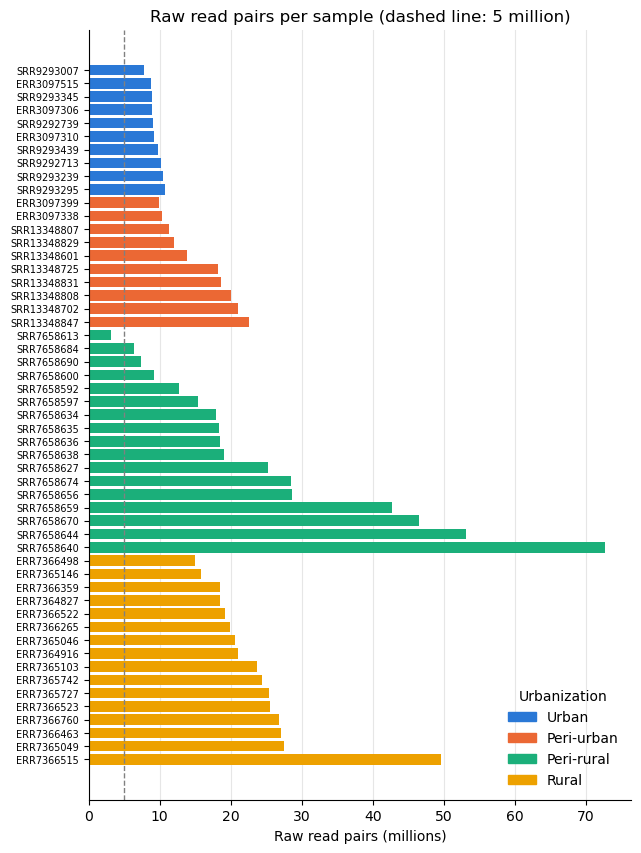

In [19]:
# Bar chart of raw read pairs per sample, grouped and coloured by urbanization level
# Chose a colorblind safe palette, but can change anytime:
colours = {"Urban": "#2a78d6", "Peri-urban": "#eb6834", "Peri-rural": "#1baf7a", "Hinterland": "#eda100"}
# In plots, the "Hinterland" level is labelled "Rural"
plot_labels = {"Hinterland": "Rural"}

# Sort by urbanization level, then by depth, for easier visualization as "blocks" of bars per level
plot_data = metadata.sort_values(["urbanization", "raw_read_pairs"])
bar_colours = [colours[level] for level in plot_data["urbanization"]]

fig, ax = plt.subplots(figsize=(7, 10))
ax.barh(plot_data.index, plot_data["raw_read_pairs"] / 1e6, color=bar_colours, height=0.8)
ax.axvline(LOW_DEPTH / 1e6, color="grey", linestyle="--", linewidth=1)   # low-depth threshold
ax.invert_yaxis()                                                          # first level at the top
ax.set_xlabel("Raw read pairs (millions)")
ax.set_title("Raw read pairs per sample (dashed line: 5 million)")
ax.tick_params(axis="y", labelsize=7)
ax.grid(axis="x", color="0.9")
ax.set_axisbelow(True)
ax.legend(handles=[Patch(color=c, label=plot_labels.get(level, level)) for level, c in colours.items()],
          title="Urbanization", frameon=False, loc="lower right")

fig.savefig(RESULTS / "01_raw_read_pairs_per_sample.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Quality profile

Median quality score at each position in the reads. The tables come from the random subsample of 10,000 reads in `demux summarize`. 

NOTE: Because the studies have different read lengths, positions after 101 bp only contain reads from the longer-read samples. 

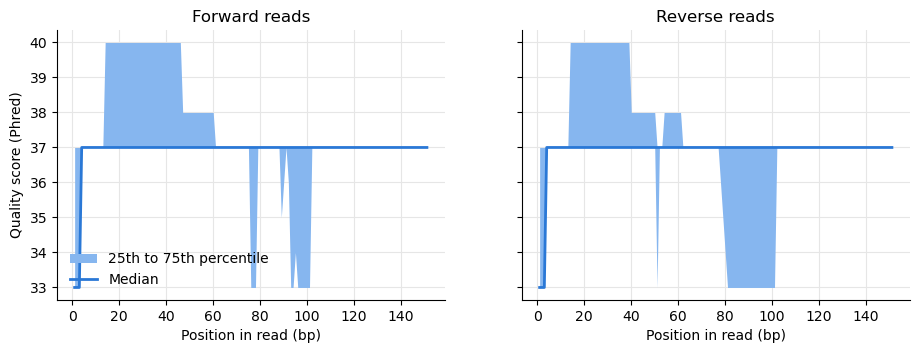

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)

for ax, direction in zip(axes, ["forward", "reverse"]):
    # Rows are percentiles (2%, 9%, 25%, 50%, ...), columns are positions in the read
    quality = pd.read_csv(RESULTS / f"01_raw_quality_{direction}.tsv", sep="\t", index_col=0)
    positions = range(1, quality.shape[1] + 1)

    ax.fill_between(positions, quality.loc["25%"], quality.loc["75%"],
                    color="#86b6ef", linewidth=0, label="25th to 75th percentile")
    ax.plot(positions, quality.loc["50%"], color="#2a78d6", linewidth=2, label="Median")
    ax.set_title(f"{direction.capitalize()} reads")
    ax.set_xlabel("Position in read (bp)")
    ax.grid(color="0.9")
    ax.set_axisbelow(True)

axes[0].set_ylabel("Quality score (Phred)")
axes[0].legend(frameon=False, loc="lower left")

fig.savefig(RESULTS / "01_raw_quality_profile.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Saving the sample overview

One row per sample. Later notebooks will add a column for each processing stage (after quality control, after host removal, classified by Kraken2, assigned by Bracken), which will give the read-tracking table.

In [21]:
overview = metadata[["country_iso3", "urbanization", "read_length", "raw_read_pairs", "low_depth"]]
overview.to_csv(RESULTS / "01_sample_overview.tsv", sep="\t", index_label="sample_id")
overview.head()

,country_iso3,urbanization,read_length,raw_read_pairs,low_depth
id,,,,,
ERR3097306,CMR,Urban,126,8937217,False
SRR9292713,CMR,Urban,126,10252447,False
SRR9293345,CMR,Urban,126,8923296,False
SRR9292739,CMR,Urban,126,9012176,False
SRR9293007,CMR,Urban,126,7825668,False
